# Pipeline Klasifikasi Aritmia EKG: Hibrida 1D-CNN dan BiLSTM pada MIT-BIH

Notebook ini menjalankan alur penelitian dari awal sampai akhir: instalasi lingkungan, pemeriksaan integritas data, pembagian data, pelatihan tiga model pada tiga skenario ketidakseimbangan kelas, evaluasi, pemilihan model untuk deployment, dan ekspor model ke format PyTorch serta ONNX.

Alur kerja:

1. Instalasi dan pemeriksaan lingkungan.
2. Konfigurasi penelitian.
3. Pemuatan data dan audit integritas.
4. Pembagian data dan distribusi kelas.
5. Strategi penanganan ketidakseimbangan kelas.
6. Definisi arsitektur (1D-CNN saja, BiLSTM saja, dan hibrida).
7. Fungsi pelatihan dan evaluasi satu run.
8. Grid eksperimen 3 model x 3 skenario x 5 seed (dapat dilanjutkan jika terputus).
9. Agregasi tabel performa.
10. Uji pasangan dan effect size.
11. Gambar untuk naskah.
12. Pemilihan model untuk deployment berdasarkan validasi.
13. Ekspor model (state dict, konfigurasi, ONNX) dan uji kesetaraan.
14. Prediktor inferensi untuk FastAPI, Streamlit, atau Next.js.
15. Ringkasan dan paket unduhan.

Pengaturan Kaggle yang diperlukan:

- Accelerator: GPU (T4 atau P100).
- Internet: On, agar pip dapat memasang onnx dan onnxruntime.
- Dataset: pasang dataset MIT-BIH format CSV (mitbih_train.csv dan mitbih_test.csv).

Sel yang diberi tag torch membutuhkan PyTorch dan dilewati jika PyTorch tidak tersedia.

Keterbatasan yang perlu dicatat: setiap baris dataset adalah satu denyut yang sudah tersegmentasi, sehingga pembagian data tidak dapat diverifikasi sebagai antarpasien. BiLSTM memproses urutan di dalam satu denyut dan tidak memodelkan ritme antardenyut. Model deployment hanya menerima denyut tersegmentasi 187 sampel, bukan rekaman EKG mentah.

## 1. Instalasi dan pemeriksaan lingkungan

In [1]:
import os
import sys
import json
import time
import random
import hashlib
import platform
import shutil
import subprocess
from datetime import datetime
from pathlib import Path

try:
    import onnx
    import onnxruntime
except ImportError:
    if os.environ.get("EKG_SKIP_INSTALL", "0") != "1":
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime"], check=False)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy import stats as sp_stats
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split

try:
    import torch
    HAS_TORCH = True
except ImportError:
    torch = None
    HAS_TORCH = False

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__, "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__)
if HAS_TORCH:
    print("PyTorch :", torch.__version__)
    print("CUDA    :", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "tidak ada GPU")
else:
    print("PyTorch belum tersedia. Sel bertanda torch akan dilewati.")

Python  : 3.10.22
NumPy   : 2.2.6 | pandas: 2.3.3 | scikit-learn: 1.7.2
PyTorch : 2.11.0+cu128
CUDA    : True | NVIDIA GeForce RTX 5060 Laptop GPU


## 2. Konfigurasi penelitian

Semua parameter penelitian dikumpulkan di satu tempat agar sinkron dengan Bab III. Variabel lingkungan `EKG_QUICK`, `EKG_MAX_EPOCHS`, `EKG_SEEDS`, dan `EKG_SUBSET` dapat dipakai untuk uji cepat tanpa mengubah kode.

In [2]:
QUICK_TEST = os.environ.get("EKG_QUICK", "0") == "1"

CONFIG = {
    "n_features": 187,
    "n_classes": 5,
    "class_codes": ["N", "S", "V", "F", "Q"],
    "class_names": {"N": "Normal", "S": "Supraventrikular", "V": "Ventrikel",
                    "F": "Fusi", "Q": "Unknown"},
    "split_seed": 42,
    "val_fraction": 0.15,
    "oversample_ratio": 0.35,
    "batch_size": 128,
    "learning_rate": 1e-3,
    "max_epochs": int(os.environ.get("EKG_MAX_EPOCHS", "1" if QUICK_TEST else "50")),
    "patience": 7,
    "lr_patience": 3,
    "lr_factor": 0.5,
    "seeds": [int(s) for s in os.environ.get("EKG_SEEDS", "42" if QUICK_TEST else "42,43,44,45,46").split(",")],
    "models": ["cnn", "bilstm", "hybrid"],
    "scenarios": ["imb1", "imb2", "imb3"],
    "subset": int(os.environ.get("EKG_SUBSET", "2000" if QUICK_TEST else "0")),
    "sampling_rate_hz": 125,
}

MODEL_LABELS = {"cnn": "1D-CNN saja", "bilstm": "BiLSTM saja", "hybrid": "Hibrida 1D-CNN dan BiLSTM"}
SCENARIO_LABELS = {"imb1": "Tanpa penanganan", "imb2": "Pembobotan kelas",
                   "imb3": "Oversampling dan pembobotan kelas"}
EXPECTED_PARAMS = {"cnn": 174469, "bilstm": 150789, "hybrid": 422277}


def find_data_dir():
    env = os.environ.get("EKG_DATA_DIR")
    if env and Path(env).exists():
        return Path(env)
    # 1. Cek folder data lokal atau direktori saat ini
    for candidate in [Path("./data"), Path("."), Path("../data")]:
        if (candidate / "mitbih_train.csv").exists():
            return candidate.resolve()
    # 2. Cek rekursif di folder lokal
    local_hits = sorted(Path(".").rglob("mitbih_train.csv"))
    if local_hits:
        return local_hits[0].parent.resolve()
    # 3. Cek di Kaggle jika berjalan di lingkungan Kaggle
    if Path("/kaggle/input").exists():
        kaggle_hits = sorted(Path("/kaggle/input").rglob("mitbih_train.csv"))
        if kaggle_hits:
            return kaggle_hits[0].parent
    raise FileNotFoundError(
        "mitbih_train.csv tidak ditemukan!\n"
        "Silakan unduh dataset MIT-BIH (mitbih_train.csv dan mitbih_test.csv)\n"
        "lalu letakkan di folder './data/' atau sejajar dengan notebook ini."
    )


DATA_DIR = find_data_dir()
def get_default_out_dir():
    if Path("/kaggle/working").exists():
        return Path("/kaggle/working/hasil_ekg")
    return Path("./hasil_ekg").resolve()

OUT_DIR = Path(os.environ.get("EKG_OUT_DIR", get_default_out_dir()))
for sub in ["runs", "checkpoints", "tabel", "gambar", "model_deploy"]:
    (OUT_DIR / sub).mkdir(parents=True, exist_ok=True)


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    if HAS_TORCH:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


CONFIG["data_dir"] = str(DATA_DIR)
CONFIG["created"] = datetime.now().isoformat(timespec="seconds")
with open(OUT_DIR / "config.json", "w", encoding="utf-8") as fh:
    json.dump(CONFIG, fh, indent=2, ensure_ascii=False)

print("Data  :", DATA_DIR)
print("Output:", OUT_DIR)
print("Mode  :", "uji cepat" if QUICK_TEST else "penuh")
print("Seed  :", CONFIG["seeds"], "| epoch maks:", CONFIG["max_epochs"], "| subset:", CONFIG["subset"] or "semua")

Data  : D:\Kuliah\Semester 5\AI\data
Output: D:\Kuliah\Semester 5\AI\hasil_ekg
Mode  : penuh
Seed  : [42, 43, 44, 45, 46] | epoch maks: 50 | subset: semua


## 3. Pemuatan data dan audit integritas

Berkas dibaca tanpa asumsi header. Setiap berkas diperiksa jumlah kolomnya, nilai hilang, dan rentang label. Rentang amplitudo diperiksa, dan jika berada di luar [0, 1], setiap denyut dinormalisasi dengan min-max per denyut. Keputusan normalisasi disimpan ke konfigurasi agar prediktor deployment memakai aturan yang sama.

Audit tumpang tindih mencari sampel yang identik persis di dalam berkas dan antara data latih dan data uji.

In [3]:
def load_csv(path):
    df = pd.read_csv(path, header=None)
    if pd.to_numeric(df.iloc[0, :], errors="coerce").isna().any():
        df = pd.read_csv(path, header=0)
    if df.shape[1] != CONFIG["n_features"] + 1:
        raise ValueError(f"{path.name}: diharapkan {CONFIG['n_features'] + 1} kolom, ditemukan {df.shape[1]}.")
    X = df.iloc[:, : CONFIG["n_features"]].to_numpy(dtype=np.float32)
    y = df.iloc[:, CONFIG["n_features"]].to_numpy()
    if not np.isfinite(X).all():
        raise ValueError(f"{path.name}: terdapat nilai NaN atau tak hingga.")
    if not np.isin(y, np.arange(CONFIG["n_classes"])).all():
        raise ValueError(f"{path.name}: terdapat label di luar rentang 0 sampai 4.")
    return X, y.astype(np.int64)


Xtr_raw, ytr_all = load_csv(DATA_DIR / "mitbih_train.csv")
Xte_raw, yte_full = load_csv(DATA_DIR / "mitbih_test.csv")
print(f"train: {Xtr_raw.shape} | test: {Xte_raw.shape}")


def range_needs_norm(X):
    return float(X.min()) < 0.0 or float(X.max()) > 1.0


NORMALIZATION = "minmax_per_beat" if (range_needs_norm(Xtr_raw) or range_needs_norm(Xte_raw)) else "none"
CONFIG["normalization"] = NORMALIZATION
with open(OUT_DIR / "config.json", "w", encoding="utf-8") as fh:
    json.dump(CONFIG, fh, indent=2, ensure_ascii=False)


def apply_normalization(X, mode=NORMALIZATION):
    if mode == "none":
        return X.astype(np.float32)
    mn = X.min(axis=1, keepdims=True)
    mx = X.max(axis=1, keepdims=True)
    return ((X - mn) / np.maximum(mx - mn, 1e-8)).astype(np.float32)


print(f"Rentang train: [{Xtr_raw.min():.6f}, {Xtr_raw.max():.6f}]")
print(f"Rentang test : [{Xte_raw.min():.6f}, {Xte_raw.max():.6f}]")
print("Mode normalisasi:", NORMALIZATION)

Xtr_all = apply_normalization(Xtr_raw)
Xte_full = apply_normalization(Xte_raw)


def row_hashes(X):
    X = np.ascontiguousarray(X)
    return [hashlib.sha1(row.tobytes()).hexdigest() for row in X]


h_tr = row_hashes(Xtr_all)
h_te = row_hashes(Xte_full)
s_tr, s_te = set(h_tr), set(h_te)
audit = {
    "jumlah_baris_train": len(h_tr),
    "jumlah_baris_test": len(h_te),
    "duplikat_dalam_train": len(h_tr) - len(s_tr),
    "duplikat_dalam_test": len(h_te) - len(s_te),
    "baris_test_identik_dengan_train": int(sum(h in s_tr for h in h_te)),
    "baris_train_identik_dengan_test": int(sum(h in s_te for h in h_tr)),
}
for key, value in audit.items():
    print(f"{key:34s}: {value}")
del h_tr, h_te, s_tr, s_te

with open(OUT_DIR / "tabel" / "audit_data.json", "w", encoding="utf-8") as fh:
    json.dump({"audit_tumpang_tindih": audit, "normalisasi": NORMALIZATION}, fh, indent=2)

if CONFIG["subset"]:
    rs = np.random.default_rng(CONFIG["split_seed"])
    i_tr = rs.choice(len(ytr_all), min(CONFIG["subset"], len(ytr_all)), replace=False)
    i_te = rs.choice(len(yte_full), min(CONFIG["subset"], len(yte_full)), replace=False)
    Xtr_all, ytr_all = Xtr_all[i_tr], ytr_all[i_tr]
    Xte, yte = Xte_full[i_te], yte_full[i_te]
    print("Mode subset aktif:", len(ytr_all), "train dan", len(yte), "test")
else:
    Xte, yte = Xte_full, yte_full


train: (87554, 187) | test: (21892, 187)
Rentang train: [0.000000, 1.000000]
Rentang test : [0.000000, 1.000000]
Mode normalisasi: none
jumlah_baris_train                : 87554
jumlah_baris_test                 : 21892
duplikat_dalam_train              : 0
duplikat_dalam_test               : 0
baris_test_identik_dengan_train   : 0
baris_train_identik_dengan_test   : 0


## 4. Pembagian data dan distribusi kelas

Data latih dibagi menjadi training set dan validation set secara stratified dengan `random_state` 42. Test set tetap utuh dan hanya dipakai untuk evaluasi akhir.

 Kode            Kelas  Training_set  Validation_set  Test_set
    N           Normal         61600           10871     18118
    S Supraventrikular          1889             334       556
    V        Ventrikel          4920             868      1448
    F             Fusi           545              96       162
    Q          Unknown          5466             965      1608
Total                -         74420           13134     21892


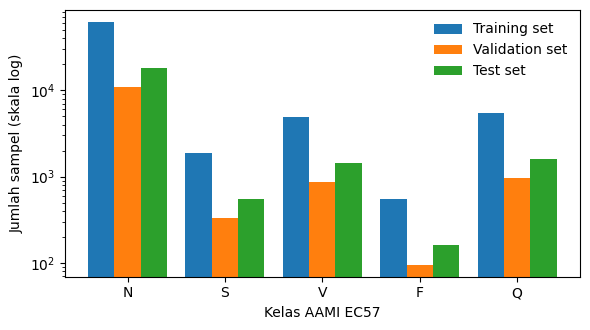

In [4]:
idx = np.arange(len(ytr_all))
tr_idx, va_idx = train_test_split(idx, test_size=CONFIG["val_fraction"], stratify=ytr_all,
                                  random_state=CONFIG["split_seed"])
tr_idx, va_idx = np.sort(tr_idx), np.sort(va_idx)
Xtr, ytr = Xtr_all[tr_idx], ytr_all[tr_idx]
Xva, yva = Xtr_all[va_idx], ytr_all[va_idx]


def distribution_table(y_tr, y_va, y_te):
    rows = []
    for c, code in enumerate(CONFIG["class_codes"]):
        rows.append({"Kode": code, "Kelas": CONFIG["class_names"][code],
                     "Training_set": int((y_tr == c).sum()),
                     "Validation_set": int((y_va == c).sum()),
                     "Test_set": int((y_te == c).sum())})
    df = pd.DataFrame(rows)
    total = {"Kode": "Total", "Kelas": "-"}
    for col in ["Training_set", "Validation_set", "Test_set"]:
        total[col] = int(df[col].sum())
    return pd.concat([df, pd.DataFrame([total])], ignore_index=True)


dist = distribution_table(ytr, yva, yte)
dist.to_csv(OUT_DIR / "tabel" / "tabel_distribusi_kelas.csv", index=False, sep=";", encoding="utf-8-sig")
print(dist.to_string(index=False))

fig, ax = plt.subplots(figsize=(6.0, 3.4))
x = np.arange(len(CONFIG["class_codes"]))
w = 0.27
ax.bar(x - w, dist.iloc[:-1]["Training_set"], w, label="Training set")
ax.bar(x, dist.iloc[:-1]["Validation_set"], w, label="Validation set")
ax.bar(x + w, dist.iloc[:-1]["Test_set"], w, label="Test set")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(CONFIG["class_codes"])
ax.set_ylabel("Jumlah sampel (skala log)")
ax.set_xlabel("Kelas AAMI EC57")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(OUT_DIR / "gambar" / "distribusi_kelas.png", dpi=300)
fig.savefig(OUT_DIR / "gambar" / "distribusi_kelas.pdf")
plt.show()


## 5. Strategi penanganan ketidakseimbangan kelas

Imb1 adalah baseline tanpa penanganan. Imb2 memakai bobot kelas berbanding terbalik frekuensi. Imb3 menambahkan random oversampling hingga 35% dari kelas mayoritas, lalu memakai bobot kelas dari distribusi hasil oversampling. Semua manipulasi hanya dilakukan pada training set.

In [5]:
def random_oversample(X, y, ratio, rng):
    counts = np.bincount(y, minlength=CONFIG["n_classes"])
    majority = int(counts.argmax())
    target = int(round(ratio * counts[majority]))
    parts_x, parts_y = [X], [y]
    for c in range(CONFIG["n_classes"]):
        if c == majority or counts[c] == 0 or counts[c] >= target:
            continue
        pick = rng.choice(np.flatnonzero(y == c), size=int(target - counts[c]), replace=True)
        parts_x.append(X[pick])
        parts_y.append(y[pick])
    X_out = np.concatenate(parts_x)
    y_out = np.concatenate(parts_y)
    perm = rng.permutation(len(y_out))
    return X_out[perm], y_out[perm]


def class_weights(y):
    counts = np.bincount(y, minlength=CONFIG["n_classes"]).astype(np.float64)
    return (len(y) / (CONFIG["n_classes"] * np.maximum(counts, 1.0))).astype(np.float32)


X_prev, y_prev = random_oversample(Xtr, ytr, CONFIG["oversample_ratio"], np.random.default_rng(CONFIG["split_seed"]))
print("Training set asli        :", np.bincount(ytr, minlength=5).tolist())
print("Setelah oversampling     :", np.bincount(y_prev, minlength=5).tolist())
print("Bobot kelas (Imb2)       :", np.round(class_weights(ytr), 4).tolist())
print("Bobot kelas (Imb3)       :", np.round(class_weights(y_prev), 4).tolist())
del X_prev, y_prev


Training set asli        : [61600, 1889, 4920, 545, 5466]
Setelah oversampling     : [61600, 21560, 21560, 21560, 21560]
Bobot kelas (Imb2)       : [0.24160000681877136, 7.879300117492676, 3.0251998901367188, 27.310100555419922, 2.7230000495910645]
Bobot kelas (Imb3)       : [0.47999998927116394, 1.371399998664856, 1.371399998664856, 1.371399998664856, 1.371399998664856]


## 6. Definisi arsitektur

Tiga model dibangun dari blok yang sama sebisa mungkin agar perbedaan performa hanya berasal dari komponen yang diuji. Blok 1D-CNN memiliki tiga lapisan konvolusi dengan 64, 128, dan 256 filter. Panjang sekuens berubah dari 187 menjadi 23 setelah tiga kali max pooling. Setiap BiLSTM memakai dua lapisan dengan 64 unit per arah.

Jumlah parameter dicek terhadap nilai yang dihitung manual untuk Bab III.

In [6]:
def make_model(name):
    nn = torch.nn

    class ConvStack(nn.Module):
        def __init__(self):
            super().__init__()

            def block(c_in, c_out, k):
                return nn.Sequential(
                    nn.Conv1d(c_in, c_out, kernel_size=k, padding=k // 2),
                    nn.BatchNorm1d(c_out),
                    nn.ReLU(),
                    nn.MaxPool1d(2),
                    nn.Dropout(0.2),
                )

            self.net = nn.Sequential(block(1, 64, 5), block(64, 128, 5), block(128, 256, 3))

        def forward(self, x):
            return self.net(x.transpose(1, 2))

    class CNNOnly(nn.Module):
        def __init__(self):
            super().__init__()
            self.conv = ConvStack()
            self.head = nn.Sequential(nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 5))

        def forward(self, x):
            return self.head(self.conv(x).mean(dim=2))

    class BiLSTMOnly(nn.Module):
        def __init__(self):
            super().__init__()
            self.rnn = nn.LSTM(1, 64, num_layers=2, batch_first=True, bidirectional=True, dropout=0.2)
            self.head = nn.Sequential(nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 5))

        def forward(self, x):
            _, (h, _) = self.rnn(x)
            return self.head(torch.cat([h[-2], h[-1]], dim=1))

    class Hybrid(nn.Module):
        def __init__(self):
            super().__init__()
            self.conv = ConvStack()
            self.rnn = nn.LSTM(256, 64, num_layers=2, batch_first=True, bidirectional=True, dropout=0.2)
            self.head = nn.Sequential(nn.Linear(128, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 5))

        def forward(self, x):
            z = self.conv(x).transpose(1, 2)
            _, (h, _) = self.rnn(z)
            return self.head(torch.cat([h[-2], h[-1]], dim=1))

    registry = {"cnn": CNNOnly, "bilstm": BiLSTMOnly, "hybrid": Hybrid}
    return registry[name]()


for name in CONFIG["models"]:
    m = make_model(name)
    n = sum(p.numel() for p in m.parameters())
    out = m(torch.zeros(4, 187, 1))
    status = "sesuai" if n == EXPECTED_PARAMS[name] else "BERBEDA"
    print(f"{name:7s} | parameter: {n:>9,d} | diharapkan: {EXPECTED_PARAMS[name]:>9,d} ({status}) | keluaran: {tuple(out.shape)}")
del m, out


cnn     | parameter:   174,469 | diharapkan:   174,469 (sesuai) | keluaran: (4, 5)
bilstm  | parameter:   150,789 | diharapkan:   150,789 (sesuai) | keluaran: (4, 5)
hybrid  | parameter:   422,277 | diharapkan:   422,277 (sesuai) | keluaran: (4, 5)


## 7. Fungsi pelatihan dan evaluasi satu run

Pelatihan memakai Adam, ReduceLROnPlateau, dan early stopping pada macro-F1 validasi. Checkpoint terbaik dipilih dari validation set. Test set tidak pernah dipakai untuk memilih apa pun.

In [7]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else
                      ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu"))
print("Perangkat:", DEVICE)


def predict(model, X, device=None):
    device = device or DEVICE
    model.eval()
    out = []
    with torch.no_grad():
        for s in range(0, len(X), 2048):
            xb = torch.from_numpy(X[s:s + 2048]).unsqueeze(-1).to(device)
            out.append(model(xb).argmax(dim=1).cpu().numpy())
    return np.concatenate(out)


def run_training(model_name, scenario, seed):
    set_seed(seed)
    rng = np.random.default_rng(seed)
    if scenario == "imb3":
        X_fit, y_fit = random_oversample(Xtr, ytr, CONFIG["oversample_ratio"], rng)
    else:
        X_fit, y_fit = Xtr, ytr
    weight = None
    if scenario in ("imb2", "imb3"):
        weight = torch.tensor(class_weights(y_fit), dtype=torch.float32, device=DEVICE)

    model = make_model(model_name).to(DEVICE)
    criterion = torch.nn.CrossEntropyLoss(weight=weight)
    optimizer = torch.optim.Adam(model.parameters(), lr=CONFIG["learning_rate"])
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=CONFIG["lr_factor"], patience=CONFIG["lr_patience"])
    n_params = int(sum(p.numel() for p in model.parameters()))

    best_f1, best_state, bad = -1.0, None, 0
    history = []
    t0 = time.time()
    for epoch in range(1, CONFIG["max_epochs"] + 1):
        model.train()
        order = rng.permutation(len(y_fit))
        losses = []
        for s in range(0, len(order), CONFIG["batch_size"]):
            b = order[s:s + CONFIG["batch_size"]]
            xb = torch.from_numpy(X_fit[b]).unsqueeze(-1).to(DEVICE)
            yb = torch.from_numpy(y_fit[b]).to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            losses.append(loss.item())
        val_pred = predict(model, Xva)
        val_f1 = f1_score(yva, val_pred, labels=list(range(CONFIG["n_classes"])), average="macro", zero_division=0)
        scheduler.step(val_f1)
        train_loss = float(np.mean(losses))
        history.append({"epoch": epoch, "train_loss": train_loss, "val_macro_f1": float(val_f1),
                        "lr": float(optimizer.param_groups[0]["lr"])})
        print(f"    epoch {epoch:02d} | loss latih {train_loss:.4f} | macro-F1 validasi {val_f1:.4f}")
        if val_f1 > best_f1 + 1e-6:
            best_f1 = float(val_f1)
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1
            if bad >= CONFIG["patience"]:
                print(f"    early stopping pada epoch {epoch}")
                break
    model.load_state_dict(best_state)
    return model, best_state, history, n_params, best_f1, time.time() - t0


Perangkat: cuda


In [8]:
def compute_metrics(y_true, y_pred):
    labels = list(range(CONFIG["n_classes"]))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    total = cm.sum()
    per_class = {}
    for c, code in enumerate(CONFIG["class_codes"]):
        tp = cm[c, c]
        fp = cm[:, c].sum() - tp
        fn = cm[c, :].sum() - tp
        tn = total - tp - fp - fn
        spec = float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0
        per_class[code] = {"precision": float(prec[c]), "recall": float(rec[c]), "f1": float(f1[c]),
                           "specificity": spec, "support": int(sup[c])}
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
        "per_class": per_class,
        "confusion_matrix": cm.tolist(),
    }


## 8. Grid eksperimen

Setiap run disimpan sebagai JSON dan checkpoint. Jika sesi Kaggle terputus, jalankan ulang sel ini dan run yang sudah selesai akan dilewati.

In [9]:
for scenario in CONFIG["scenarios"]:
    for model_name in CONFIG["models"]:
        for seed in CONFIG["seeds"]:
            tag = f"{scenario}_{model_name}_s{seed}"
            json_path = OUT_DIR / "runs" / f"{tag}.json"
            if json_path.exists():
                print("lewati (sudah ada):", tag)
                continue
            print("\nLatih:", tag)
            model, best_state, history, n_params, best_val, elapsed = run_training(model_name, scenario, seed)
            ckpt_rel = f"checkpoints/{tag}.pt"
            torch.save(best_state, OUT_DIR / ckpt_rel)
            y_pred = predict(model, Xte)
            metrics = compute_metrics(yte, y_pred)
            record = {"scenario": scenario, "model": model_name, "seed": seed,
                      "epochs_run": len(history), "n_params": n_params,
                      "best_val_macro_f1": best_val, "train_seconds": round(elapsed, 1),
                      "checkpoint": ckpt_rel, "history": history, "test": metrics}
            with open(json_path, "w", encoding="utf-8") as fh:
                json.dump(record, fh, indent=2, ensure_ascii=False)
            print(f"  test: akurasi {metrics['accuracy']:.4f} | macro-F1 {metrics['macro_f1']:.4f} | {elapsed / 60:.1f} menit")
            del model
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()



Latih: imb1_cnn_s42
    epoch 01 | loss latih 0.3057 | macro-F1 validasi 0.6774
    epoch 02 | loss latih 0.1804 | macro-F1 validasi 0.6737
    epoch 03 | loss latih 0.1565 | macro-F1 validasi 0.8036
    epoch 04 | loss latih 0.1415 | macro-F1 validasi 0.8338
    epoch 05 | loss latih 0.1346 | macro-F1 validasi 0.8516
    epoch 06 | loss latih 0.1264 | macro-F1 validasi 0.8304
    epoch 07 | loss latih 0.1219 | macro-F1 validasi 0.8607
    epoch 08 | loss latih 0.1183 | macro-F1 validasi 0.8599
    epoch 09 | loss latih 0.1137 | macro-F1 validasi 0.8770
    epoch 10 | loss latih 0.1100 | macro-F1 validasi 0.8689
    epoch 11 | loss latih 0.1064 | macro-F1 validasi 0.8797
    epoch 12 | loss latih 0.1033 | macro-F1 validasi 0.8807
    epoch 13 | loss latih 0.1017 | macro-F1 validasi 0.8878
    epoch 14 | loss latih 0.0995 | macro-F1 validasi 0.8833
    epoch 15 | loss latih 0.0961 | macro-F1 validasi 0.8892
    epoch 16 | loss latih 0.0953 | macro-F1 validasi 0.8802
    epoch 17 | loss

## 9. Agregasi tabel performa

Rata-rata, simpangan baku (SD), dan interval kepercayaan 95% dihitung dari lima run per konfigurasi. Distribusi t dengan derajat kebebasan n-1 dipakai karena jumlah seed kecil. Semua angka menggunakan koma desimal dan pemisah titik koma agar mudah dibuka di Excel versi Indonesia.

In [10]:
def load_runs():
    recs = []
    for p in sorted((OUT_DIR / "runs").glob("*.json")):
        with open(p, encoding="utf-8") as fh:
            recs.append(json.load(fh))
    return recs


def t_critical(df):
    return float(sp_stats.t.ppf(0.975, df))


def mean_sd_ci(values):
    v = np.asarray(values, dtype=float)
    n = len(v)
    mean = float(v.mean())
    if n < 2:
        return mean, 0.0, mean, mean
    sd = float(v.std(ddof=1))
    half = t_critical(n - 1) * sd / np.sqrt(n)
    return mean, sd, mean - half, mean + half


def fmt_pct(x):
    return f"{x * 100:.2f}".replace(".", ",")


def fmt_num(x, nd=1):
    return f"{x:.{nd}f}".replace(".", ",")


def fmt_ms(mean, sd):
    return f"{fmt_pct(mean)} ± {fmt_pct(sd)}"


records = load_runs()
print("Jumlah run termuat:", len(records))


def export_tables(records):
    run_rows, summary_rows, class_rows = [], [], []
    for r in records:
        t = r["test"]
        run_rows.append({"Skenario": SCENARIO_LABELS[r["scenario"]], "Model": MODEL_LABELS[r["model"]],
                         "Seed": r["seed"], "Akurasi_persen": fmt_pct(t["accuracy"]),
                         "Macro_F1_persen": fmt_pct(t["macro_f1"]),
                         "Weighted_F1_persen": fmt_pct(t["weighted_f1"]),
                         "Epoch_berjalan": r["epochs_run"], "Parameter": r["n_params"],
                         "Validasi_macro_F1_persen": fmt_pct(r["best_val_macro_f1"]),
                         "Waktu_latih_menit": fmt_num(r["train_seconds"] / 60, 1)})
    pd.DataFrame(run_rows).to_csv(OUT_DIR / "tabel" / "metrik_per_run.csv", index=False,
                                  sep=";", encoding="utf-8-sig")

    for scenario in CONFIG["scenarios"]:
        for model_name in CONFIG["models"]:
            grp = [r for r in records if r["scenario"] == scenario and r["model"] == model_name]
            if not grp:
                continue
            acc = mean_sd_ci([r["test"]["accuracy"] for r in grp])
            mf1 = mean_sd_ci([r["test"]["macro_f1"] for r in grp])
            wf1 = mean_sd_ci([r["test"]["weighted_f1"] for r in grp])
            summary_rows.append({
                "Skenario": SCENARIO_LABELS[scenario], "Model": MODEL_LABELS[model_name],
                "Jumlah_seed": len(grp), "Parameter": grp[0]["n_params"],
                "Akurasi_persen": fmt_ms(acc[0], acc[1]),
                "Macro_F1_persen": fmt_ms(mf1[0], mf1[1]),
                "Weighted_F1_persen": fmt_ms(wf1[0], wf1[1]),
                "Akurasi_CI95_bawah": fmt_pct(acc[2]), "Akurasi_CI95_atas": fmt_pct(acc[3]),
                "Macro_F1_CI95_bawah": fmt_pct(mf1[2]), "Macro_F1_CI95_atas": fmt_pct(mf1[3]),
                "Rata_rata_epoch": fmt_num(np.mean([r["epochs_run"] for r in grp]), 1),
            })
            for code in CONFIG["class_codes"]:
                row = {"Skenario": SCENARIO_LABELS[scenario], "Model": MODEL_LABELS[model_name],
                       "Kelas": f"{code} ({CONFIG['class_names'][code]})",
                       "Jumlah_uji": grp[0]["test"]["per_class"][code]["support"]}
                for metric, label in [("precision", "Presisi"), ("recall", "Recall"),
                                      ("f1", "F1"), ("specificity", "Spesifisitas")]:
                    vals = [r["test"]["per_class"][code][metric] for r in grp]
                    m_, s_, _, _ = mean_sd_ci(vals)
                    row[f"{label}_persen"] = fmt_ms(m_, s_)
                class_rows.append(row)

    pd.DataFrame(summary_rows).to_csv(OUT_DIR / "tabel" / "tabel_performa_ringkasan.csv",
                                      index=False, sep=";", encoding="utf-8-sig")
    pd.DataFrame(class_rows).to_csv(OUT_DIR / "tabel" / "tabel_performa_per_kelas.csv",
                                    index=False, sep=";", encoding="utf-8-sig")
    return pd.DataFrame(summary_rows), pd.DataFrame(class_rows)


summary_df, class_df = export_tables(records)
display_cols = ["Skenario", "Model", "Akurasi_persen", "Macro_F1_persen", "Weighted_F1_persen"]
print(summary_df[display_cols].to_string(index=False) if len(summary_df) else "Belum ada run.")


Jumlah run termuat: 45
                         Skenario                     Model Akurasi_persen Macro_F1_persen Weighted_F1_persen
                 Tanpa penanganan               1D-CNN saja   98,30 ± 0,07    90,38 ± 0,36       98,21 ± 0,08
                 Tanpa penanganan               BiLSTM saja   98,41 ± 0,08    91,39 ± 0,59       98,37 ± 0,09
                 Tanpa penanganan Hibrida 1D-CNN dan BiLSTM   98,70 ± 0,12    92,40 ± 0,74       98,67 ± 0,13
                 Pembobotan kelas               1D-CNN saja   92,99 ± 1,26    76,39 ± 1,62       93,93 ± 1,06
                 Pembobotan kelas               BiLSTM saja   93,31 ± 1,78    77,46 ± 4,06       94,25 ± 1,37
                 Pembobotan kelas Hibrida 1D-CNN dan BiLSTM   95,95 ± 0,98    83,36 ± 2,64       96,37 ± 0,80
Oversampling dan pembobotan kelas               1D-CNN saja   96,10 ± 0,58    84,37 ± 1,47       96,45 ± 0,58
Oversampling dan pembobotan kelas               BiLSTM saja   98,17 ± 0,07    90,85 ± 0,47       

## 10. Uji pasangan dan effect size

Perbandingan model dilakukan dengan memasangkan run berdasarkan seed, karena setiap seed memakai pembagian data yang sama. Dilaporkan selisih rata-rata, interval kepercayaan 95% dari selisih, nilai p dari uji t berpasangan, dan effect size dz. Dengan lima seed, nilai p dari uji Wilcoxon tidak dapat turun di bawah 0,0625 dua sisi, sehingga uji t berpasangan dan interval kepercayaan menjadi laporan utama.

In [11]:
R = {(r["scenario"], r["model"], r["seed"]): r for r in records}
stat_rows = []
for sc in CONFIG["scenarios"]:
    for ref in ["cnn", "bilstm"]:
        seeds_ok = [s for s in CONFIG["seeds"] if (sc, "hybrid", s) in R and (sc, ref, s) in R]
        if len(seeds_ok) < 2:
            continue
        for metric, label in [("macro_f1", "Macro-F1"), ("accuracy", "Akurasi")]:
            a = np.array([R[(sc, "hybrid", s)]["test"][metric] for s in seeds_ok])
            b = np.array([R[(sc, ref, s)]["test"][metric] for s in seeds_ok])
            d = a - b
            t_stat, p_val = sp_stats.ttest_rel(a, b)
            sd_d = float(d.std(ddof=1))
            dz = float(d.mean() / sd_d) if sd_d > 0 else float("nan")
            half = t_critical(len(d) - 1) * sd_d / np.sqrt(len(d))
            stat_rows.append({
                "Skenario": SCENARIO_LABELS[sc],
                "Pembanding": f"Hibrida vs {MODEL_LABELS[ref]}",
                "Metrik": label,
                "Jumlah_pasangan": len(d),
                "Selisih_rata_persen": fmt_pct(float(d.mean())),
                "CI95_bawah_persen": fmt_pct(float(d.mean()) - half),
                "CI95_atas_persen": fmt_pct(float(d.mean()) + half),
                "p_t_berpasangan": f"{p_val:.4f}".replace(".", ",") if np.isfinite(p_val) else "-",
                "Effect_size_dz": f"{dz:.2f}".replace(".", ",") if np.isfinite(dz) else "-",
            })
stat_df = pd.DataFrame(stat_rows)
stat_df.to_csv(OUT_DIR / "tabel" / "uji_pasangan_hibrida.csv", index=False, sep=";", encoding="utf-8-sig")
print(stat_df.to_string(index=False) if len(stat_df) else "Belum cukup pasangan run untuk uji.")


                         Skenario             Pembanding   Metrik  Jumlah_pasangan Selisih_rata_persen CI95_bawah_persen CI95_atas_persen p_t_berpasangan Effect_size_dz
                 Tanpa penanganan Hibrida vs 1D-CNN saja Macro-F1                5                2,01              1,49             2,54          0,0004           4,75
                 Tanpa penanganan Hibrida vs 1D-CNN saja  Akurasi                5                0,40              0,33             0,48          0,0001           6,77
                 Tanpa penanganan Hibrida vs BiLSTM saja Macro-F1                5                1,01              0,46             1,56          0,0071           2,27
                 Tanpa penanganan Hibrida vs BiLSTM saja  Akurasi                5                0,30              0,16             0,43          0,0033           2,80
                 Pembobotan kelas Hibrida vs 1D-CNN saja Macro-F1                5                6,97              4,92             9,01          0,0007  

## 11. Gambar untuk naskah

Gambar disimpan dalam PNG 300 dpi dan PDF. Kurva pembelajaran memakai seed pertama. Matriks konfusi merupakan jumlah dari lima seed dengan persentase per baris dan jumlah sampel di dalam sel.

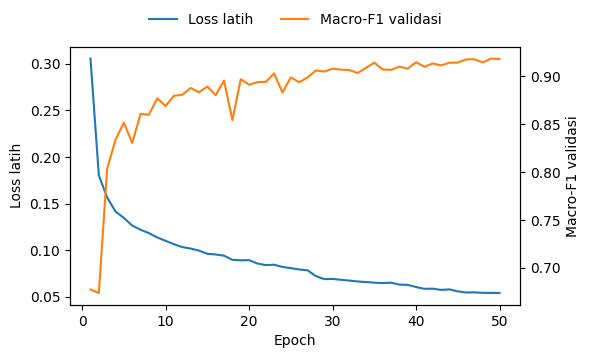

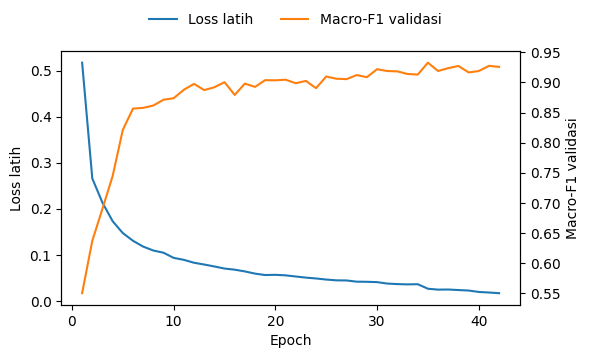

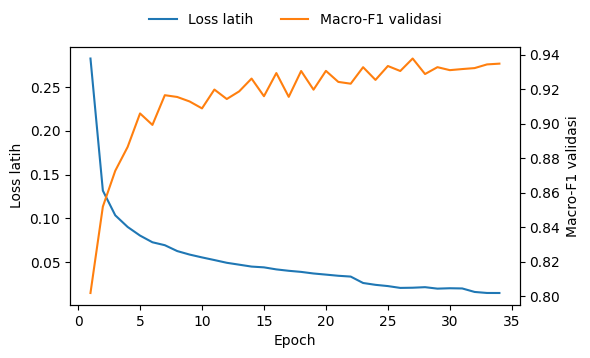

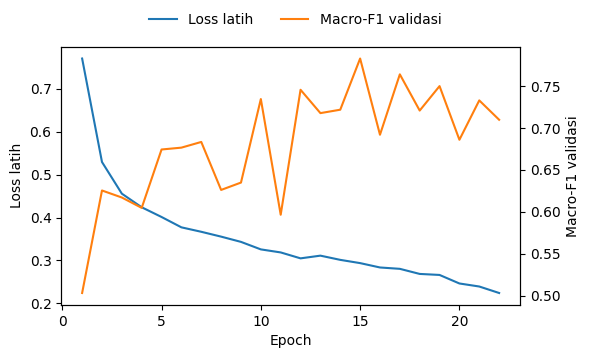

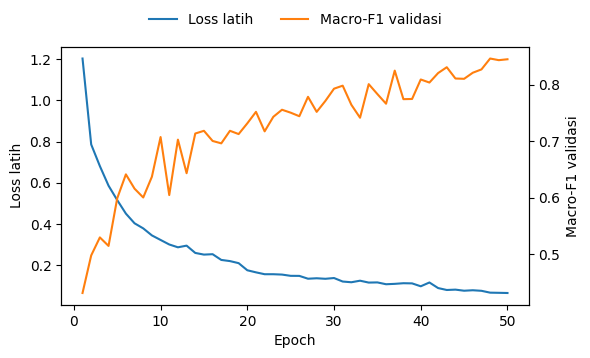

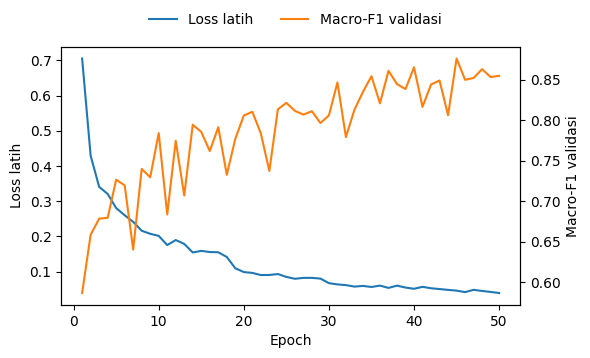

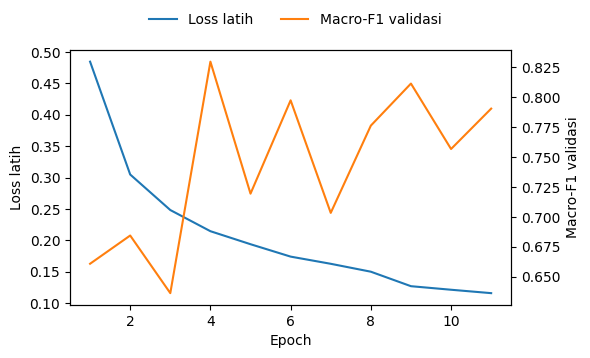

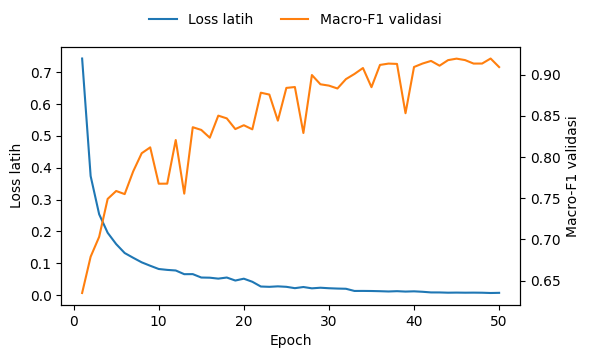

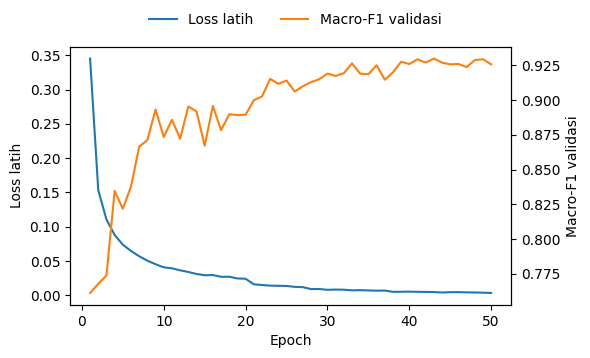

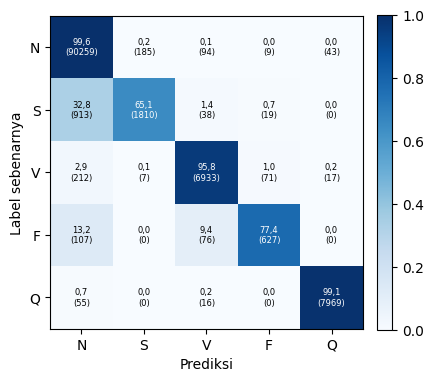

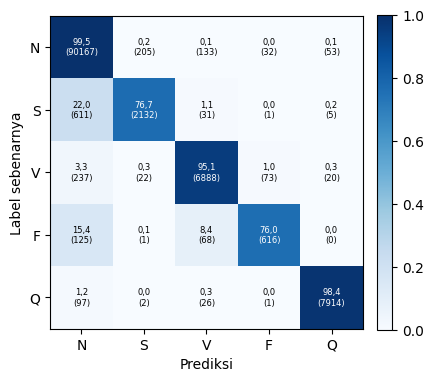

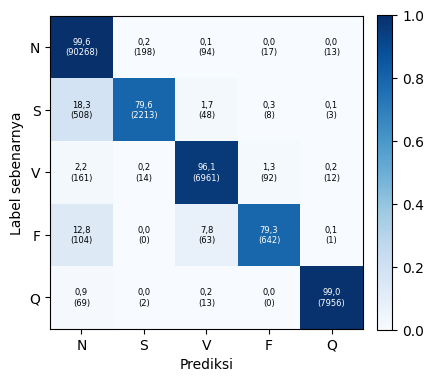

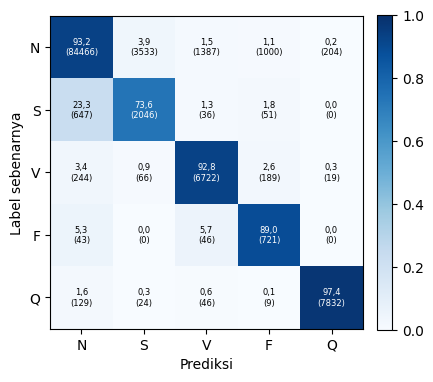

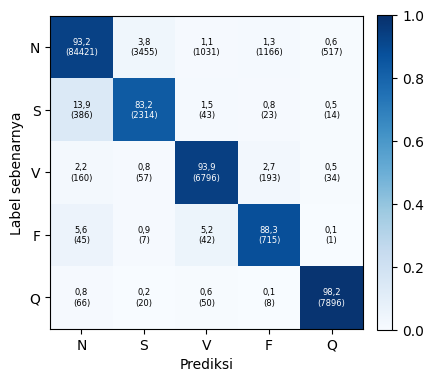

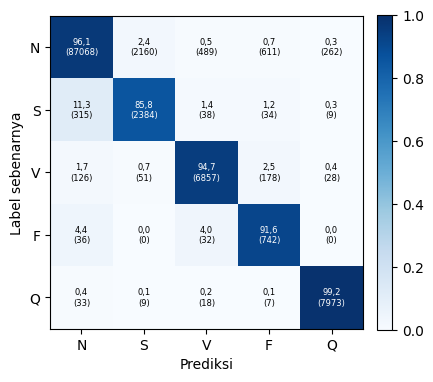

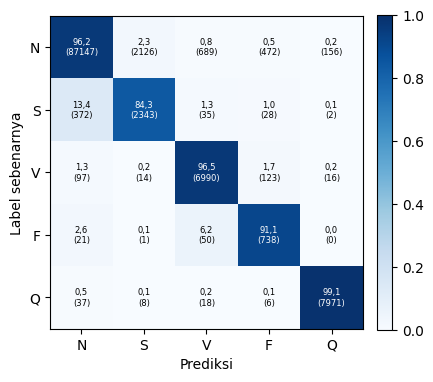

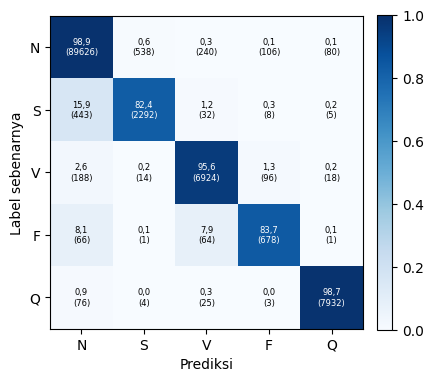

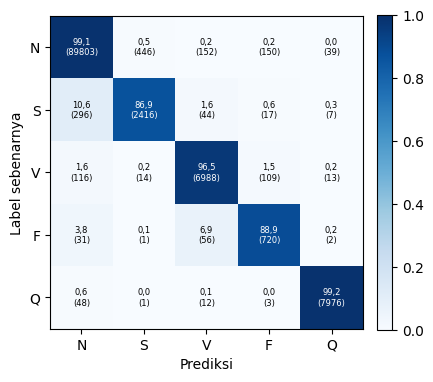

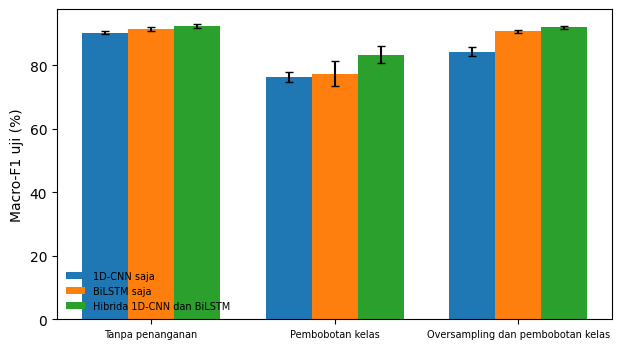

In [12]:
def fig_save(fig, stem):
    fig.savefig(OUT_DIR / "gambar" / f"{stem}.png", dpi=300)
    fig.savefig(OUT_DIR / "gambar" / f"{stem}.pdf")
    plt.show()
    plt.close(fig)


for scenario in CONFIG["scenarios"]:
    for model_name in CONFIG["models"]:
        grp = sorted([r for r in records if r["scenario"] == scenario and r["model"] == model_name],
                     key=lambda r: r["seed"])
        if not grp:
            continue
        hist = grp[0]["history"]
        ep = [h["epoch"] for h in hist]
        fig, ax1 = plt.subplots(figsize=(6.0, 3.6))
        ax1.plot(ep, [h["train_loss"] for h in hist], color="tab:blue", label="Loss latih")
        ax1.set_xlabel("Epoch")
        ax1.set_ylabel("Loss latih")
        ax2 = ax1.twinx()
        ax2.plot(ep, [h["val_macro_f1"] for h in hist], color="tab:orange", label="Macro-F1 validasi")
        ax2.set_ylabel("Macro-F1 validasi")
        h1, l1 = ax1.get_legend_handles_labels()
        h2, l2 = ax2.get_legend_handles_labels()
        fig.legend(h1 + h2, l1 + l2, loc="upper center", ncol=2, frameon=False)
        fig.tight_layout(rect=(0, 0, 1, 0.92))
        fig_save(fig, f"kurva_{scenario}_{model_name}")

for scenario in CONFIG["scenarios"]:
    for model_name in CONFIG["models"]:
        grp = [r for r in records if r["scenario"] == scenario and r["model"] == model_name]
        if not grp:
            continue
        cm = np.sum([np.array(r["test"]["confusion_matrix"]) for r in grp], axis=0)
        cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
        fig, ax = plt.subplots(figsize=(4.4, 4.0))
        im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
        for i in range(CONFIG["n_classes"]):
            for j in range(CONFIG["n_classes"]):
                txt = f"{cm_norm[i, j] * 100:.1f}".replace(".", ",")
                ax.text(j, i, f"{txt}\n({cm[i, j]})", ha="center", va="center", fontsize=6,
                        color="white" if cm_norm[i, j] > 0.5 else "black")
        ax.set_xticks(range(CONFIG["n_classes"]))
        ax.set_yticks(range(CONFIG["n_classes"]))
        ax.set_xticklabels(CONFIG["class_codes"])
        ax.set_yticklabels(CONFIG["class_codes"])
        ax.set_xlabel("Prediksi")
        ax.set_ylabel("Label sebenarnya")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        fig.tight_layout()
        fig_save(fig, f"matriks_konfusi_{scenario}_{model_name}")

if len(summary_df):
    fig, ax = plt.subplots(figsize=(6.4, 3.6))
    width = 0.25
    x = np.arange(len(CONFIG["scenarios"]))
    for k, model_name in enumerate(CONFIG["models"]):
        means, sds = [], []
        for scenario in CONFIG["scenarios"]:
            grp = [r for r in records if r["scenario"] == scenario and r["model"] == model_name]
            m_, s_, _, _ = mean_sd_ci([r["test"]["macro_f1"] for r in grp]) if grp else (np.nan, np.nan, 0, 0)
            means.append(m_ * 100)
            sds.append(s_ * 100)
        ax.bar(x + (k - 1) * width, means, width, yerr=sds, capsize=3, label=MODEL_LABELS[model_name])
    ax.set_xticks(x)
    ax.set_xticklabels([SCENARIO_LABELS[s] for s in CONFIG["scenarios"]], fontsize=7)
    ax.set_ylabel("Macro-F1 uji (%)")
    ax.legend(frameon=False, fontsize=7)
    fig.tight_layout()
    fig_save(fig, "perbandingan_macro_f1")


## 12. Pemilihan model untuk deployment

Model deployment dipilih dari seluruh run hibrida berdasarkan macro-F1 validasi tertinggi. Test set tidak dipakai untuk memilih. Setelah dipilih, checkpoint dimuat ulang dan metrik ujinya dihitung ulang untuk memastikan konsisten dengan hasil grid.

In [13]:
hybrid_runs = [r for r in records if r["model"] == "hybrid"]
if not hybrid_runs:
    raise RuntimeError("Belum ada run hibrida. Jalankan sel grid eksperimen terlebih dahulu.")

best_run = max(hybrid_runs, key=lambda r: r["best_val_macro_f1"])
print(f"Dipilih: {best_run['scenario']} | seed {best_run['seed']} | "
      f"macro-F1 validasi {best_run['best_val_macro_f1']:.4f}")

deploy_model = make_model("hybrid")
deploy_model.load_state_dict(torch.load(OUT_DIR / best_run["checkpoint"], map_location="cpu"))
deploy_model.eval()

y_chk = predict(deploy_model, Xte, device=torch.device("cpu"))
chk = compute_metrics(yte, y_chk)
assert abs(chk["macro_f1"] - best_run["test"]["macro_f1"]) < 1e-6, "Metrik uji tidak konsisten dengan run"
print(f"Verifikasi ulang macro-F1 uji: {chk['macro_f1']:.4f} (konsisten dengan grid)")


Dipilih: imb1 | seed 45 | macro-F1 validasi 0.9398
Verifikasi ulang macro-F1 uji: 0.9241 (konsisten dengan grid)


## 13. Ekspor model

Model diekspor ke tiga bentuk. Berkas `model_state_dict.pt` berisi bobot PyTorch. Berkas `model.onnx` dipakai untuk inferensi lintas bahasa, misalnya FastAPI, Streamlit, atau ONNX Runtime Web untuk Next.js. Berkas `model_config.json` mencatat kontrak masukan dan keluaran. Kesetaraan keluaran PyTorch dan ONNX diuji di akhir sel.

In [14]:
DEPLOY = OUT_DIR / "model_deploy"
DEPLOY.mkdir(parents=True, exist_ok=True)
torch.save(deploy_model.state_dict(), DEPLOY / "model_state_dict.pt")

deploy_model = deploy_model.cpu().eval()
onnx_path = DEPLOY / "model.onnx"
dummy = torch.zeros(1, CONFIG["n_features"], 1)
export_kwargs = dict(
    input_names=["ekg_beat"],
    output_names=["logits"],
    dynamic_axes={"ekg_beat": {0: "batch"}, "logits": {0: "batch"}},
    opset_version=17,
)
try:
    torch.onnx.export(deploy_model, dummy, str(onnx_path), dynamo=False, **export_kwargs)
except TypeError:
    torch.onnx.export(deploy_model, dummy, str(onnx_path), **export_kwargs)

import onnxruntime as ort
sess = ort.InferenceSession(str(onnx_path), providers=["CPUExecutionProvider"])
sample = Xte[:512]
with torch.no_grad():
    ref = deploy_model(torch.from_numpy(sample).unsqueeze(-1)).numpy()
out_onnx = sess.run(["logits"], {"ekg_beat": sample[:, :, None].astype(np.float32)})[0]
max_diff = float(np.abs(ref - out_onnx).max())
print(f"Selisih maksimum logits PyTorch vs ONNX: {max_diff:.2e}")
if max_diff > 1e-3:
    raise RuntimeError("Ekspor ONNX tidak setara dengan PyTorch. Periksa versi torch dan opset.")

config_deploy = {
    "nama_model": "Hibrida 1D-CNN dan BiLSTM untuk klasifikasi denyut aritmia",
    "versi": "1.0.0",
    "sumber_run": {"skenario": best_run["scenario"], "model": best_run["model"], "seed": best_run["seed"]},
    "masukan": {
        "nama": "ekg_beat",
        "bentuk": ["batch", 187, 1],
        "tipe": "float32",
        "frekuensi_sampling_hz": CONFIG["sampling_rate_hz"],
        "normalisasi": NORMALIZATION,
        "syarat": "denyut tersegmentasi 187 sampel, berpusat pada puncak R, bukan rekaman mentah",
    },
    "keluaran": {
        "nama": "logits",
        "bentuk": ["batch", 5],
        "aktivasi": "softmax dihitung di luar model",
        "kelas": [{"indeks": i, "kode": c, "nama": CONFIG["class_names"][c]}
                  for i, c in enumerate(CONFIG["class_codes"])],
    },
    "arsitektur": {
        "blok_cnn": [[1, 64, 5], [64, 128, 5], [128, 256, 3]],
        "bilstm_lapisan": 2,
        "bilstm_unit_per_arah": 64,
        "head": [128, 5],
        "parameter": int(sum(p.numel() for p in deploy_model.parameters())),
    },
    "metrik_validasi_macro_f1": best_run["best_val_macro_f1"],
    "metrik_uji": {"akurasi": best_run["test"]["accuracy"],
                   "macro_f1": best_run["test"]["macro_f1"],
                   "weighted_f1": best_run["test"]["weighted_f1"]},
    "pemilihan_model": "macro-F1 validasi tertinggi di antara seluruh run hibrida, tanpa melihat test set",
    "onnx": {"opset": 17, "berkas": "model.onnx", "selisih_maks_pytorch_vs_onnx": max_diff},
    "lingkungan": {"python": platform.python_version(), "torch": torch.__version__,
                   "numpy": np.__version__, "scikit_learn": sklearn.__version__},
    "dibuat": datetime.now().isoformat(timespec="seconds"),
}
with open(DEPLOY / "model_config.json", "w", encoding="utf-8") as fh:
    json.dump(config_deploy, fh, indent=2, ensure_ascii=False)

contoh = []
for i in range(5):
    logit = sess.run(["logits"], {"ekg_beat": Xte[i:i + 1, :, None].astype(np.float32)})[0]
    contoh.append({"masukan": [round(float(v), 6) for v in Xte[i]],
                   "label_benar": int(yte[i]),
                   "logits": [round(float(v), 6) for v in logit[0]]})
with open(DEPLOY / "contoh_masukan.json", "w", encoding="utf-8") as fh:
    json.dump(contoh, fh, indent=2)

print("Berkas deployment:")
for p in sorted(DEPLOY.iterdir()):
    print(f"  {p.name:28s} {p.stat().st_size / 1024:10,.1f} KB")


C:\Users\farro\AppData\Local\Temp\ipykernel_9516\593624442.py:15: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(deploy_model, dummy, str(onnx_path), dynamo=False, **export_kwargs)
c:\Users\farro\anaconda3\envs\ekg-mitbih\lib\site-packages\torch\onnx\_internal\torchscript_exporter\symbolic_opset9.py:4463: UserWarning: Exporting a model to ONNX with a batch_size other than 1, with a variable length with LSTM can cause an error when running the ONNX model with a different batch size. Make sure to save the model with a batch size of 1, or define the initial states (h0/c0) as inputs of the model. 
  return _generic_rnn(


Selisih maksimum logits PyTorch vs ONNX: 1.14e-05
Berkas deployment:
  contoh_masukan.json                14.4 KB
  model.onnx                      1,652.6 KB
  model_config.json                   2.0 KB
  model_state_dict.pt             1,666.6 KB


## 14. Prediktor inferensi

Prediktor ini hanya bergantung pada ONNX Runtime, NumPy, dan berkas konfigurasi. Kode yang sama dapat dipindahkan ke FastAPI, Streamlit, atau layanan lain tanpa membawa PyTorch.

In [15]:
def load_predictor(model_dir=None):
    import onnxruntime as ort
    model_dir = Path(model_dir) if model_dir else (OUT_DIR / "model_deploy")
    with open(model_dir / "model_config.json", encoding="utf-8") as fh:
        cfg = json.load(fh)
    sess = ort.InferenceSession(str(model_dir / "model.onnx"), providers=["CPUExecutionProvider"])
    return {"cfg": cfg, "sess": sess}


def predict_beats(predictor, beats):
    cfg = predictor["cfg"]
    X = np.asarray(beats, dtype=np.float32)
    if X.ndim == 1:
        X = X[None, :]
    if X.ndim != 2 or X.shape[1] != cfg["masukan"]["bentuk"][1]:
        raise ValueError("Masukan harus berbentuk (n, 187): n denyut dengan 187 sampel.")
    if cfg["masukan"]["normalisasi"] == "minmax_per_beat":
        mn = X.min(axis=1, keepdims=True)
        mx = X.max(axis=1, keepdims=True)
        X = (X - mn) / np.maximum(mx - mn, 1e-8)
    logits = predictor["sess"].run(["logits"], {"ekg_beat": X[:, :, None].astype(np.float32)})[0]
    e = np.exp(logits - logits.max(axis=1, keepdims=True))
    probs = e / e.sum(axis=1, keepdims=True)
    kelas = cfg["keluaran"]["kelas"]
    hasil = []
    for pr in probs:
        i = int(pr.argmax())
        hasil.append({"indeks": i, "kode": kelas[i]["kode"], "nama": kelas[i]["nama"],
                      "probabilitas": {k["kode"]: float(p) for k, p in zip(kelas, pr)}})
    return hasil


In [16]:
pred = load_predictor()
print("Uji prediktor pada 3 denyut uji pertama:")
for hasil, benar in zip(predict_beats(pred, Xte[:3]), yte[:3]):
    print(f"  label benar: {CONFIG['class_codes'][int(benar)]} | prediksi: {hasil['kode']} ({hasil['nama']})")

import time as _t
satu = Xte[:1]
t0 = _t.perf_counter()
for _ in range(500):
    predict_beats(pred, satu)
rata_ms = (_t.perf_counter() - t0) / 500 * 1000
print(f"Rata-rata latensi satu denyut di CPU: {rata_ms:.3f} ms")


Uji prediktor pada 3 denyut uji pertama:
  label benar: N | prediksi: N (Normal)
  label benar: N | prediksi: N (Normal)
  label benar: N | prediksi: N (Normal)
Rata-rata latensi satu denyut di CPU: 0.734 ms


## 15. Ringkasan dan paket unduhan

Semua tabel, gambar, dan model dikumpulkan dalam satu arsip. Unduh arsip tersebut dari panel Output Kaggle.

In [17]:
print("Isi folder hasil:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file() and "checkpoints" not in p.parts:
        print(f"  {p.relative_to(OUT_DIR)}")

arsip = shutil.make_archive(str(OUT_DIR), "zip", root_dir=OUT_DIR)
print("\nArsip:", arsip, f"({Path(arsip).stat().st_size / 1024 / 1024:.1f} MB)")


Isi folder hasil:
  config.json
  gambar\distribusi_kelas.pdf
  gambar\distribusi_kelas.png
  gambar\kurva_imb1_bilstm.pdf
  gambar\kurva_imb1_bilstm.png
  gambar\kurva_imb1_cnn.pdf
  gambar\kurva_imb1_cnn.png
  gambar\kurva_imb1_hybrid.pdf
  gambar\kurva_imb1_hybrid.png
  gambar\kurva_imb2_bilstm.pdf
  gambar\kurva_imb2_bilstm.png
  gambar\kurva_imb2_cnn.pdf
  gambar\kurva_imb2_cnn.png
  gambar\kurva_imb2_hybrid.pdf
  gambar\kurva_imb2_hybrid.png
  gambar\kurva_imb3_bilstm.pdf
  gambar\kurva_imb3_bilstm.png
  gambar\kurva_imb3_cnn.pdf
  gambar\kurva_imb3_cnn.png
  gambar\kurva_imb3_hybrid.pdf
  gambar\kurva_imb3_hybrid.png
  gambar\matriks_konfusi_imb1_bilstm.pdf
  gambar\matriks_konfusi_imb1_bilstm.png
  gambar\matriks_konfusi_imb1_cnn.pdf
  gambar\matriks_konfusi_imb1_cnn.png
  gambar\matriks_konfusi_imb1_hybrid.pdf
  gambar\matriks_konfusi_imb1_hybrid.png
  gambar\matriks_konfusi_imb2_bilstm.pdf
  gambar\matriks_konfusi_imb2_bilstm.png
  gambar\matriks_konfusi_imb2_cnn.pdf
  gambar